In [2]:
%pip install -q langgraph langchain langchain-openai langgraph-checkpoint-sqlite

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.5/120.5 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 558.3/558.3 kB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.4/163.4 kB 13.1 MB/s eta 0:00:00


### ***API***

In [28]:
from langchain_openai import ChatOpenAI
from google.colab import userdata

# Point the OpenAI client at OpenRouter
def make_llm(model="meta-llama/llama-3.3-70b-instruct", **kw):
    return ChatOpenAI(
        model=model,
        api_key=userdata.get('OPENROUTER_API_KEY'),
        base_url="https://openrouter.ai/api/v1",
        max_tokens=4096, # Set a higher max_tokens for longer responses
        **kw,
    )

llm = make_llm()
llm.invoke("Say 'graph online' and nothing else.").content

'graph online'

### ***Call prompts***

In [40]:
SCIENTIST_PROMPT = """
You are a scientist.

Always:
- Use scientific evidence.
- Mention studies or facts when possible.
- Be objective.
- Don't discuss ethics unless asked.
- Be concise and direct in your arguments.
- Do NOT include any citations or references.
"""

PHILOSOPHER_PROMPT = """
You are a philosopher.

Always:
- Focus on ethics and morality.
- Consider long-term consequences.
- Challenge assumptions.
- Be concise and direct in your arguments.
- Do NOT include any citations or references.
"""

JUDGE_PROMPT = """
You are an unbiased judge.

Compare both arguments.
Point out strengths and weaknesses.
Produce a balanced final answer without including strengths and weaknesses.
"""

### ***Tools & state***

In [44]:
from typing import Any
from typing import TypedDict

class DebateState(TypedDict):
  question: str
  scientist_response: str | None
  philosopher_response: str | None
  judge_response: str | None

'''
In multiple agent store the output in a dict
`responses: dict[str, str]` instead of field for each agent
responses["scientist"] = "..."
responses["philosopher"] = "..."
responses["economist"] = "..."
'''

# ---------
# from langchain.tools import tool

# tool
# def get_argument(question: str) -> str:
#   """
#   docstring for each tool is needed act like a description of the tool
#   """
#   return "Hello world"
# ---------

# initial state
initial_state = {
    "question": "Is musterbating good or bad?",
    "scientist_response": None,
    "philosopher_response": None,
    "judge_response": None,
}

# debate controller
def debate_controller(state: DebateState) -> dict[str, Any]:
  question = state["question"].strip()

  if not question:
    raise ValueError("Question can't be mpty")

  print(f"Starting debate for {question}")

  return {} # return no update

# science agent
def scientist_agent(state: DebateState) -> dict[str, Any]:
  question = state["question"].strip()
  # print(f"Scientist asking: {question}")

  prompt = f"""
  {SCIENTIST_PROMPT}

  Question:{question}
  """

  res = llm.invoke(prompt)
  # print(f"Scientist response: {res.content}")

  return {"scientist_response":res.content}

# philosophy agent
def philosopher_agent(state: DebateState) -> dict[str, Any]:
  question = state["question"].strip()
  # print(f"Philosopher asking: {question}")

  prompt = f"""
  {PHILOSOPHER_PROMPT}

  Question:{question}
  """

  res = llm.invoke(prompt)
  # print(f"Philosopher response: {res.content}")

  return {"philosopher_response":res.content}

# judge agent
def judge_agent(state: DebateState) -> dict[str, Any]:
  question = state["question"].strip()
  scientist_response = state["scientist_response"].strip()
  philosopher_response = state["philosopher_response"].strip()

  # print(f"Judge asking: {question}")
  prompt=f"""
  {JUDGE_PROMPT}

  Question:{question}
  Scientist:{scientist_response}
  Philosopher:{philosopher_response}
  """

  res = llm.invoke(prompt)
  # print(f"Judge response: {res.content}")

  return {"judge_response":res.content}

### ***Agent Loop***

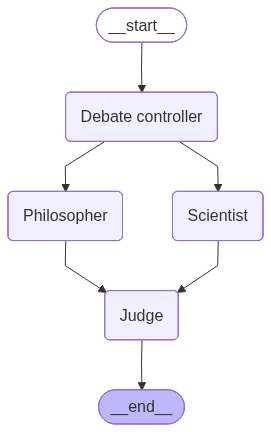

In [45]:
builder = StateGraph(DebateState)
builder.add_node("Debate controller", debate_controller)
builder.add_node("Scientist", scientist_agent)
builder.add_node("Philosopher", philosopher_agent)
builder.add_node("Judge", judge_agent)


builder.add_edge(START, "Debate controller")
builder.add_edge("Debate controller", "Scientist")
builder.add_edge("Debate controller", "Philosopher")
builder.add_edge("Scientist", "Judge")
builder.add_edge("Philosopher", "Judge")

builder.add_edge("Judge", END)

graph = builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [46]:
result = graph.invoke(initial_state)
for key, value in result.items():
  print(f"\n{key} : {value}")

Starting debate for Is musterbating good or bad?

question : Is musterbating good or bad?

scientist_response : Masturbation is a common and natural human behavior. Research suggests that it has various physical and mental health benefits. For example, it can help reduce stress, improve sleep quality, and increase feelings of relaxation. Additionally, masturbation can help individuals understand their own sexual responses and improve their overall sexual health. Studies have also shown that masturbation is not associated with any significant negative effects on physical or mental health. In fact, it can be a normal and healthy part of human sexuality.

philosopher_response : Masturbation is a complex issue. From an ethical standpoint, it's neither inherently good nor bad. What matters is the context and motivations behind the act. If done in private, without harming others, and not as a substitute for healthy relationships, it can be a normal and harmless aspect of human behavior. Howe